Polynomial Regression    
y=β0+β1X+β2X2+......+βnXn


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('prediction_traffic(new).csv')
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,date_time,hour,day_of_week,month,weather_main_Clouds,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
0,5545,0,0.530370,-0.007463,-0.027228,2012-10-02 09:00:00,9,1,10,1,...,0,0,0,0,0,0,0,7.071068e-01,-0.707107,0
1,4516,0,0.611341,-0.007463,-0.027228,2012-10-02 10:00:00,10,1,10,1,...,0,0,0,0,0,0,0,5.000000e-01,-0.866025,0
2,4767,0,0.627836,-0.007463,-0.027228,2012-10-02 11:00:00,11,1,10,1,...,0,0,0,0,0,0,0,2.588190e-01,-0.965926,0
3,5026,0,0.669071,-0.007463,-0.027228,2012-10-02 12:00:00,12,1,10,1,...,0,0,0,0,0,0,0,1.224647e-16,-1.000000,0
4,4918,0,0.744794,-0.007463,-0.027228,2012-10-02 13:00:00,13,1,10,1,...,0,0,0,0,0,0,0,-2.588190e-01,-0.965926,0


In [ ]:
df.set_index('date_time', inplace=True)
df.sort_index(inplace=True)

In [ ]:
correlation = df.corr()['traffic_volume'].abs().sort_values(ascending=False)
print(correlation)

selected_features_corr = correlation[correlation > 0.05].index.tolist()

print("\n=== Features with |correlation| > 0.05 ===")
print(selected_features_corr)

traffic_volume               1.000000
hour_cos                     0.764252
hour                         0.352401
hour_sin                     0.244211
is_weekend                   0.218647
day_of_week                  0.149544
temp                         0.130299
weather_main_Clouds          0.122285
weather_main_Mist            0.061734
holiday                      0.042897
weather_main_Fog             0.038868
weather_main_Snow            0.030804
weather_main_Haze            0.020778
weather_main_Thunderstorm    0.019241
weather_main_Rain            0.010676
weather_main_Squall          0.005493
rain_1h                      0.004714
weather_main_Drizzle         0.003082
month                        0.002533
snow_1h                      0.000733
weather_main_Smoke           0.000227
Name: traffic_volume, dtype: float64

=== Features with |correlation| > 0.05 ===
['traffic_volume', 'hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'temp', 'weather_main_Clouds', 'weather_m

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#define features and target
selected_features_corr.remove('traffic_volume')

X = df[selected_features_corr]
y = df['traffic_volume']

print("Selected features for Linear Regression:", X.columns.tolist())


Selected features for Linear Regression: ['hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'temp', 'weather_main_Clouds', 'weather_main_Mist']


In [ ]:
split_date = '2018-01-01'

train = df[df.index < split_date]
test = df[df.index >= split_date]

# Define X and y for both sets
X_train = train[selected_features_corr]
y_train = train['traffic_volume']

X_test = test[selected_features_corr]
y_test = test['traffic_volume']

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import numpy as np

# Find Optimal Polynomial Degree
degrees = range(1, 5)
cv_scores = []
train_scores = []

for degree in degrees:
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly_train = poly.fit_transform(X_train)

    # Fit model
    model = LinearRegression()
    model.fit(X_poly_train, y_train)

    # Training score
    train_scores.append(model.score(X_poly_train, y_train))

    # Cross-validation score
    cv_score = cross_val_score(model, X_poly_train, y_train
                               , cv=5, scoring='r2').mean()
    cv_scores.append(cv_score)

    print(f"Degree {degree}: Train R² = {train_scores[-1]:.4f}, CV R² = {cv_score:.4f}")

# Find optimal degree
optimal_degree = degrees[np.argmax(cv_scores)]
print(f"\n✅ Optimal degree: {optimal_degree}")

# Train R² = How well the model fits the data it was trained on
# CV R² = How well the model predicts new, unseen data

Degree 1: Train R² = 0.7143, CV R² = 0.7113
Degree 2: Train R² = 0.8594, CV R² = 0.8010
Degree 3: Train R² = 0.9278, CV R² = -0.0070
Degree 4: Train R² = 0.9366, CV R² = -1021.3190

✅ Optimal degree: 2


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Create polynomial features (degree = optimal degree)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)


In [ ]:
# Train polynomial regression
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
# Predictions
y_pred_poly = poly_model.predict(X_test_poly)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Evaluate
mae = mean_absolute_error(y_test, y_pred_poly)
mse = mean_squared_error(y_test, y_pred_poly)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_poly)
mape = np.mean(np.abs((y_test - y_pred_poly)/y_test)) * 100

print("=== Polynomial Regression (degree=2) ===")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("MAPE:", mape)

=== Polynomial Regression (degree=2) ===
MAE: 539.2839964875961
RMSE: 750.3425522626441
R2 Score: 0.8553631025963463
MAPE: 29.668082631016595


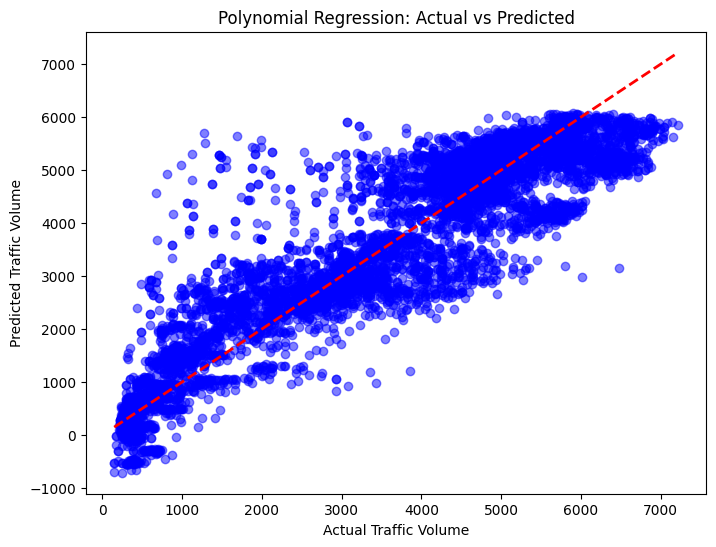

In [ ]:
import matplotlib.pyplot as plt

# Plot 1: Actual vs Predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_poly, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.show()

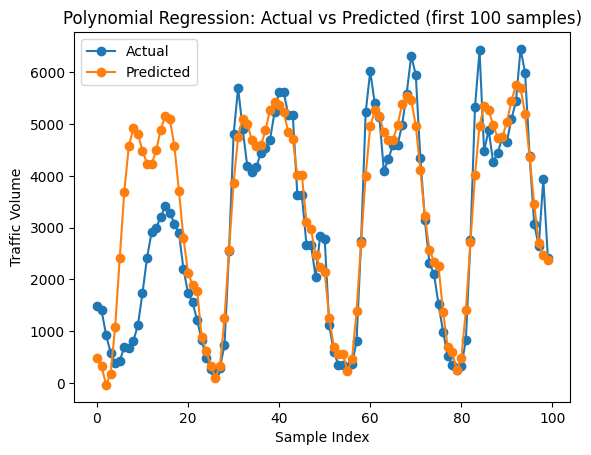

In [ ]:
import matplotlib.pyplot as plt

#plt.figure(figsize=(10,6))
plt.plot(range(100), y_test.iloc[:100], label='Actual', marker='o')
plt.plot(range(100), y_pred_poly[:100], label='Predicted', marker='o')
plt.xlabel('Sample Index')
plt.ylabel('Traffic Volume')
plt.title("Polynomial Regression: Actual vs Predicted (first 100 samples)")
plt.legend()
plt.show()


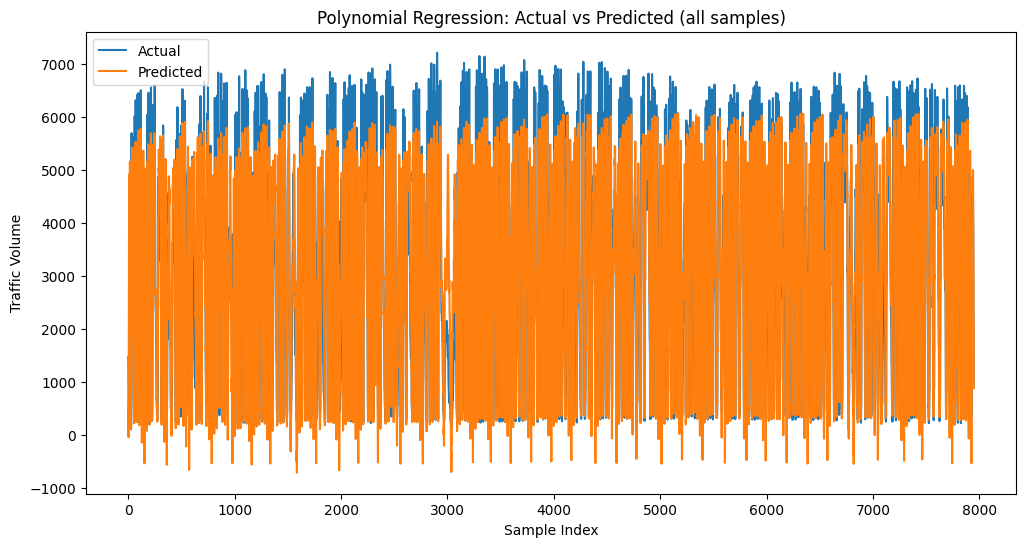

In [ ]:
#Plot result
import matplotlib.pyplot as plt

# Plot 1: Full series with predictions
plt.figure(figsize=(12,6))

# Reset index so x-axis is 0,1,2,... for all samples
y_test_reset = y_test.reset_index(drop=True)

plt.plot(y_test_reset, label='Actual')
plt.plot(y_pred_poly, label='Predicted')
plt.xlabel('Sample Index')
plt.ylabel('Traffic Volume')
plt.title("Polynomial Regression: Actual vs Predicted (all samples)")
plt.legend()
plt.show()


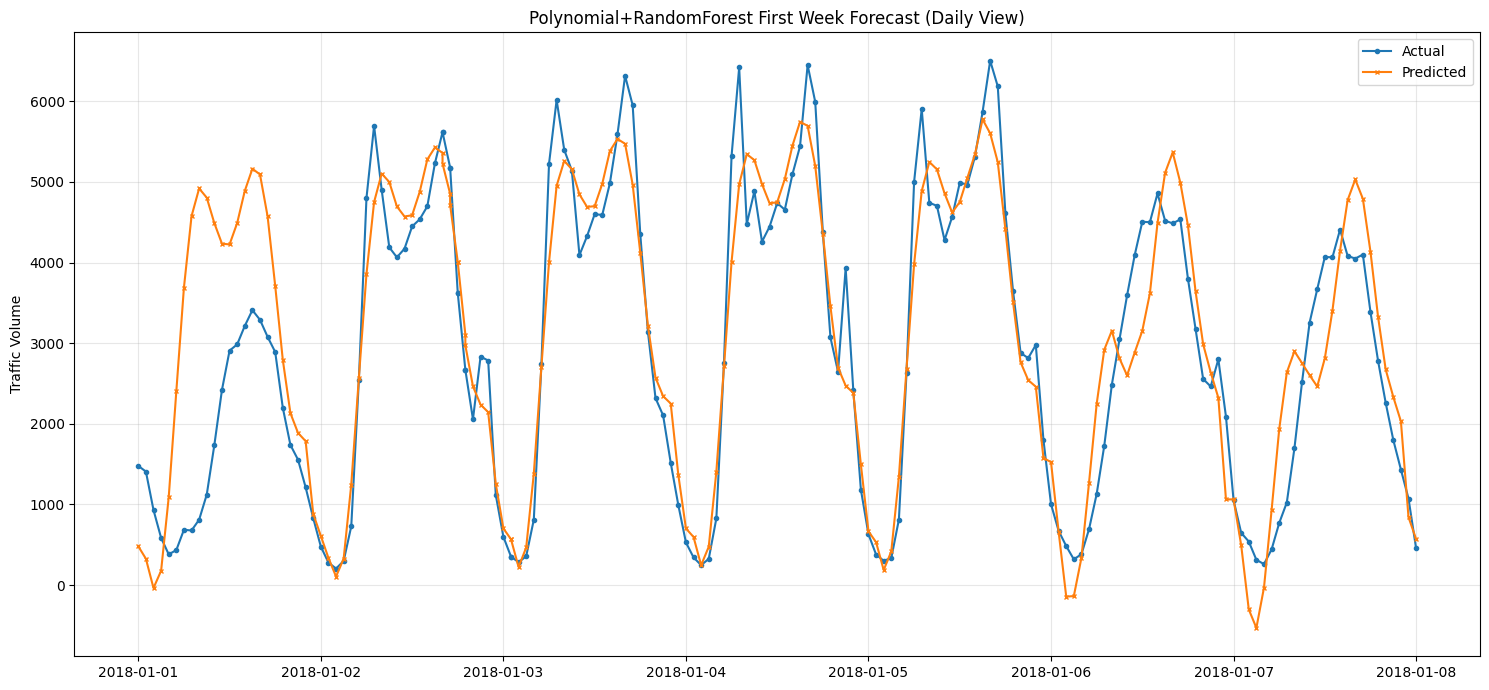

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

y_test.index = pd.to_datetime(y_test.index)

test_start = y_test.index[0]
test_first_week = test_start + pd.Timedelta(days=7)
mask = (y_test.index >= test_start) & (y_test.index <= test_first_week)

plt.figure(figsize=(15,7))

plt.plot(y_test.index[mask], y_test[mask], label='Actual', marker='o', markersize=3)
plt.plot(y_test.index[mask], y_pred_poly[mask], label='Predicted', marker='x', markersize=3)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.title('Polynomial+RandomForest First Week Forecast (Daily View)')
plt.ylabel('Traffic Volume')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Residuals

In [ ]:
residuals = y_test - y_pred_poly

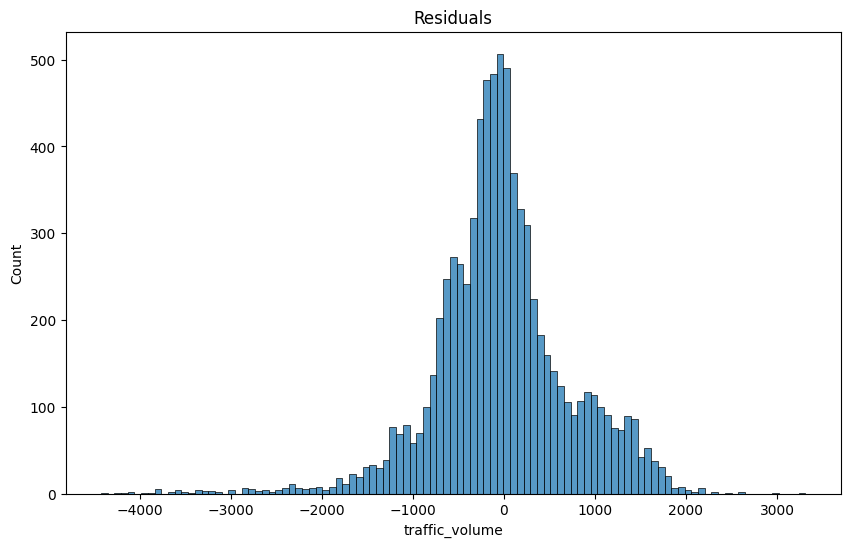

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#plot residuals
plt.figure(figsize=(10,6))
sns.histplot(residuals)
plt.title('Residuals')
plt.show()

Forecast (1 year)

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Create future dates for 1 year
future_dates = pd.date_range(start=pd.to_datetime('2018-10-01') + timedelta(hours=1),
                            periods=365*24, freq='h')

def create_future_features(future_dates, df):
    future_df = pd.DataFrame({'date_time': future_dates})

    # Extract basic time features
    future_df['hour'] = future_df['date_time'].dt.hour
    future_df['day_of_week'] = future_df['date_time'].dt.dayofweek

    # Create the same engineered features you used in training
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour']/24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour']/24)
    future_df['is_weekend'] = future_df['day_of_week'].isin([5, 6]).astype(int)

    future_df['temp'] = df['temp'].mean()
    future_df['weather_main_Clouds'] = 1
    future_df['weather_main_Clear'] = 1
    future_df['weather_main_Mist'] = 1

    future_df = future_df.set_index('date_time')
    future_X = future_df[X.columns]

    return future_df, future_X

# Create future features
future_df, future_X = create_future_features(future_dates, df)

In [ ]:
future_X_poly = poly.transform(future_X)
future_df['predicted_traffic'] = poly_model.predict(future_X_poly)

# Simple confidence interval (±10% as example)
future_df['lower_ci'] = future_df['predicted_traffic'] * 0.9
future_df['upper_ci'] = future_df['predicted_traffic'] * 1.1

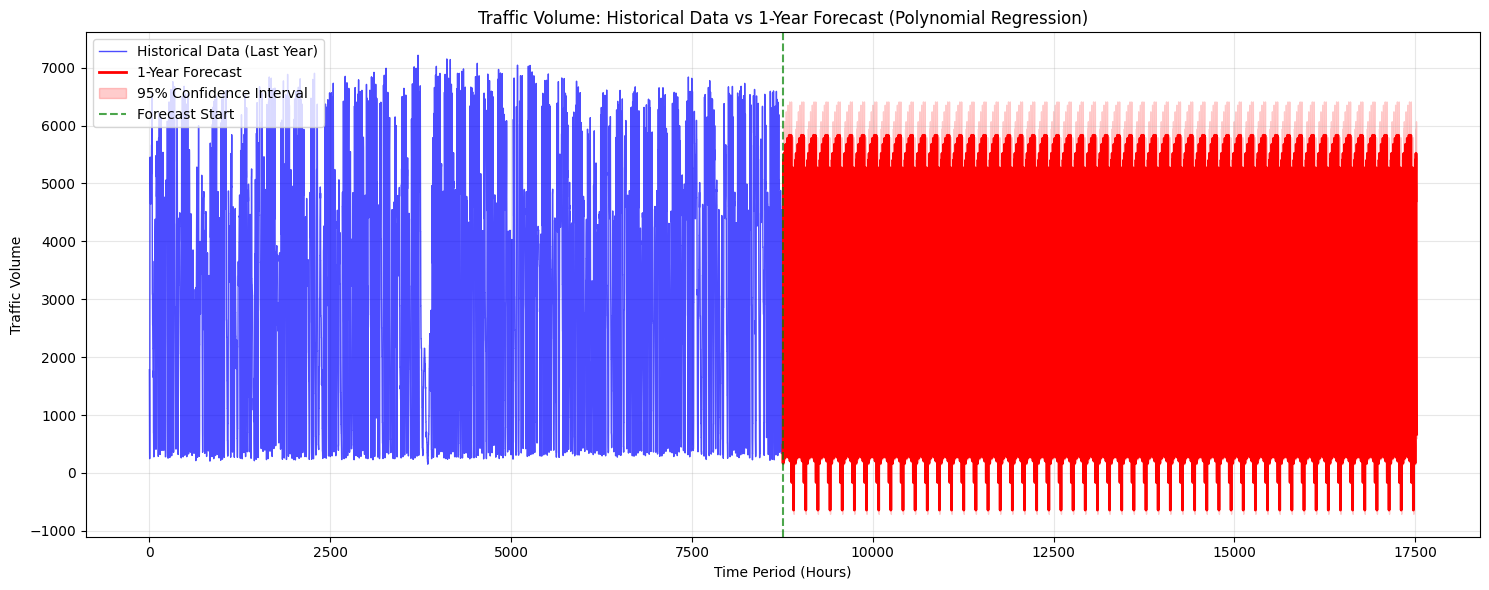

In [ ]:
plt.figure(figsize=(15,6))

# Historical data (last year)
historical_data = df['traffic_volume'].iloc[-365*24:]
historical_indices = range(len(historical_data))
plt.plot(historical_indices, historical_data,
         label='Historical Data (Last Year)', color='blue', alpha=0.7, linewidth=1)

# Forecast
forecast_indices = range(len(historical_data), len(historical_data) + len(future_df))
plt.plot(forecast_indices, future_df['predicted_traffic'],
         label='1-Year Forecast', color='red', linewidth=2)

# Confidence interval
plt.fill_between(forecast_indices,
                 future_df['lower_ci'],
                 future_df['upper_ci'],
                 color='red', alpha=0.2, label='95% Confidence Interval')

# Vertical line for forecast start
plt.axvline(x=len(historical_data), color='green', linestyle='--',
            alpha=0.7, label='Forecast Start')

plt.title('Traffic Volume: Historical Data vs 1-Year Forecast (Polynomial Regression)')
plt.xlabel('Time Period (Hours)')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Forecast (1 week)

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Create future dates for 1 year
future_dates = pd.date_range(start=pd.to_datetime('2018-10-01') + timedelta(hours=1),
                            periods=7*24, freq='h')

def create_future_features(future_dates, df):
    future_df = pd.DataFrame({'date_time': future_dates})

    # Extract basic time features
    future_df['hour'] = future_df['date_time'].dt.hour
    future_df['day_of_week'] = future_df['date_time'].dt.dayofweek

    # Create the same engineered features you used in training
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour']/24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour']/24)
    future_df['is_weekend'] = future_df['day_of_week'].isin([5, 6]).astype(int)

    future_df['temp'] = df['temp'].mean()
    future_df['weather_main_Clouds'] = 1
    future_df['weather_main_Clear'] = 1
    future_df['weather_main_Mist'] = 1

    future_df = future_df.set_index('date_time')
    future_X = future_df[X.columns]

    return future_df, future_X

# Create future features
future_df, future_X = create_future_features(future_dates, df)

In [ ]:
future_X_poly = poly.transform(future_X)
future_df['predicted_traffic'] = poly_model.predict(future_X_poly)

# Simple confidence interval (±10% as example)
future_df['lower_ci'] = future_df['predicted_traffic'] * 0.9
future_df['upper_ci'] = future_df['predicted_traffic'] * 1.1

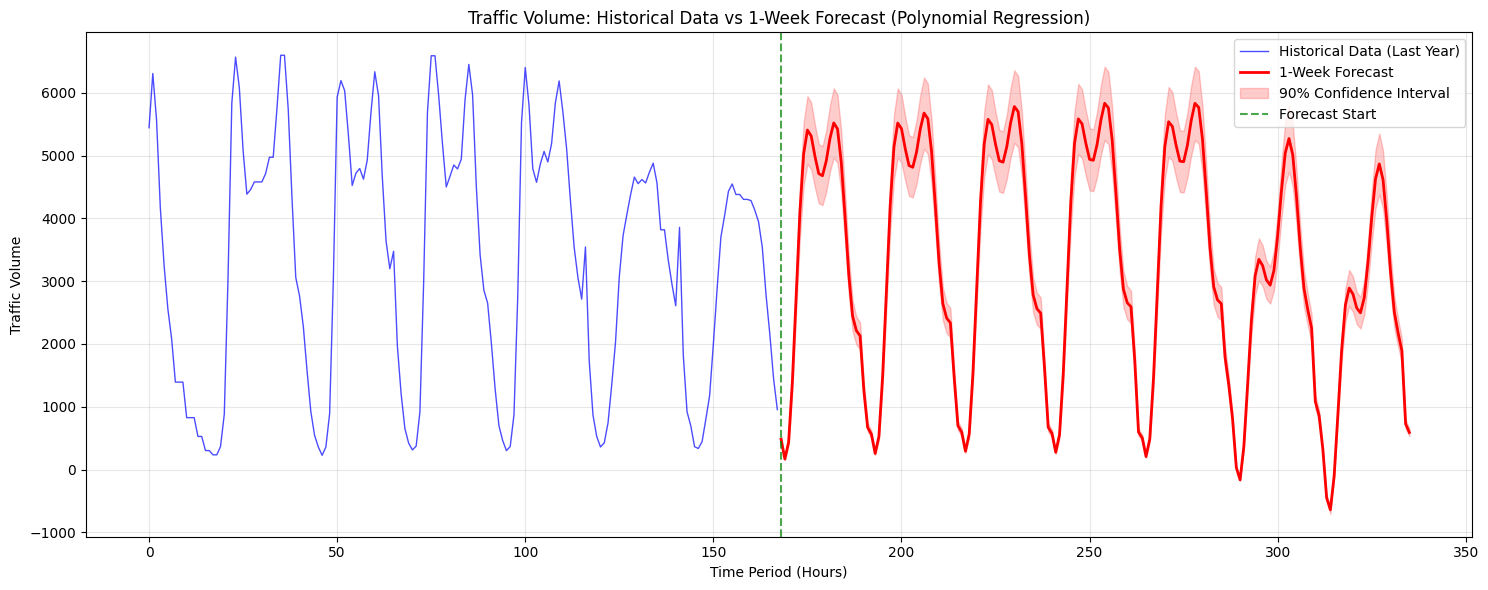

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

# Historical data (last week)
historical_data = df['traffic_volume'].iloc[-7*24:]
historical_indices = range(len(historical_data))
plt.plot(historical_indices, historical_data,
         label='Historical Data (Last Year)', color='blue', alpha=0.7, linewidth=1)

# Forecast
forecast_indices = range(len(historical_data), len(historical_data) + len(future_df))
plt.plot(forecast_indices, future_df['predicted_traffic'],
         label='1-Week Forecast', color='red', linewidth=2)

# Confidence interval
plt.fill_between(forecast_indices,
                 future_df['lower_ci'],
                 future_df['upper_ci'],
                 color='red', alpha=0.2, label='90% Confidence Interval')

# Vertical line for forecast start
plt.axvline(x=len(historical_data), color='green', linestyle='--',
            alpha=0.7, label='Forecast Start')

plt.title('Traffic Volume: Historical Data vs 1-Week Forecast (Polynomial Regression)')
plt.xlabel('Time Period (Hours)')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
